# Bagian 2 — Varian 1 — Penentuan k dengan Metode Elbow

**Proyek Akhir Pembelajaran Mesin (INF62325) · Cabang C — Klastering K-Means**
**S1 Informatika · UIN Siber Syekh Nurjati Cirebon**

| | |
|---|---|
| Pertemuan | dikerjakan setelah Pertemuan 12, dipresentasikan Pertemuan 14 |
| Tahap resmi | Tahap 2 — Varian Eksperimen 1 |
| Dikerjakan oleh | **Anggota 1** saja |
| Berkas yang dibutuhkan | `data_bersih.csv` dari Bagian 1 |
| Luaran wajib | `data/hasil_varian/varian1.json`, `gambar/varian1_elbow.png` |
| Dinilai pada | Progres 2, Pertemuan 14, **35% perorangan** |
| Tenggat | selesai sebelum Pertemuan 14 |

| | |
|---|---|
| Kelompok | Kelompok 4 (Kelas 5B) |
| Paket dataset | 5B-4 — IBM HR Employee Attrition |
| Nama dan NIM | Noval Adrian (2488010018) — Anggota 1 (Varian 1: Metode Elbow) |

---

## Panduan Bagian 2

> **Ketentuan Varian 1:** *Metode Elbow untuk k = 2 sampai 10, lalu tentukan titik sikunya.*

Bagian ini dikerjakan **Anggota 1 saja**, dan dinilai **perorangan**. Jangan menjalankan Bagian milik anggota lain: riwayat commit dipakai sebagai bukti siapa mengerjakan apa.

**Urutan kerja**

1. Jalankan 2.0 (persiapan).
2. Jalankan 2.1. Sel itu memastikan `data_bersih.csv` sudah ada di folder Drive kelompok.
3. Jalankan 2.2. Perhatikan nilai inertia tiap k dan posisi titik sikunya.
4. Periksa dan sesuaikan jawaban interpretasi di 2.3 dengan kalimat Anda sendiri. Interpretasi inilah yang paling banyak membedakan nilai antaranggota.
5. Jalankan 2.4 untuk mengunduh hasil, lalu commit dengan akun GitHub **Anda sendiri**.
6. Pastikan `data/hasil_varian/varian1.json` sudah tersimpan di folder Drive kelompok untuk dipakai bersama di Bagian 5.

**Yang perlu dipahami lebih dulu**

Inertia adalah jumlah kuadrat jarak setiap titik ke pusat klasternya. Nilainya **selalu** turun ketika k dinaikkan, jadi "inertia terkecil" bukan jawaban — kalau k disamakan dengan jumlah baris, inertia menjadi nol dan hasilnya tidak berguna. Yang dicari adalah titik di mana penurunan mulai melandai, karena di situ penambahan klaster berhenti memberi manfaat berarti.

Menunjuk siku dengan mata sering berbeda antarorang. Sel 2.2 memakai cara yang dapat diperiksa ulang: **jarak tegak lurus terjauh** dari garis yang menghubungkan titik k terkecil ke titik k terbesar. Yang dinilai bukan besarnya angka, melainkan apakah titik siku ditentukan dengan cara yang dapat dijelaskan.

Silhouette ikut dihitung di sini, tetapi hanya sebagai metrik pendukung. Dasar Bagian ini adalah inertia.

---

## 2.0 Persiapan — **jalankan setiap kali notebook dibuka**

Sesi Colab menghapus seluruh berkasnya setiap kali runtime dimulai ulang. Karena itu hasil kerja tidak disimpan di sesi Colab, melainkan di **satu folder Google Drive** yang dipakai bersama sepanjang Pertemuan 12 sampai 15. Empat sel di bawah menghubungkan folder itu, memasang pustaka, menulis `alat.py`, dan menyiapkan fungsi pembantu. Keempatnya dijalankan lebih dulu, apa pun yang Anda kerjakan di notebook ini.

`alat.py` berisi fungsi yang dipakai ketiga varian. **Jangan mengubahnya sendiri-sendiri:** kalau satu anggota mengubah isi berkas ini, ketiga varian berhenti sebanding dan tabel perbandingan menjadi tidak sah.

In [1]:
# Folder Drive ini adalah tempat serah-terima antar pertemuan: apa pun yang
# ditulis di sini terbaca kembali oleh notebook pertemuan berikutnya.
import os
import sys
from google.colab import drive

drive.mount('/content/drive')

FOLDER = '/content/drive/MyDrive/ProyekML_KlasteringKMeans'
os.makedirs(FOLDER, exist_ok=True)
os.chdir(FOLDER)      # sejak baris ini, 'data/...' berarti di dalam FOLDER

if FOLDER not in sys.path:
    sys.path.insert(0, FOLDER)   # agar 'import alat' menemukan berkas di folder ini

for d in ('data', 'data/hasil_varian', 'model', 'gambar'):
    os.makedirs(d, exist_ok=True)

print('Folder proyek:', FOLDER)
print('Isi folder   :', sorted(os.listdir()) or '(masih kosong)')

Mounted at /content/drive
Folder proyek: /content/drive/MyDrive/ProyekML_KlasteringKMeans
Isi folder   : ['__pycache__', 'alat.py', 'data', 'gambar', 'model']


In [2]:
import ast, json, os, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn

warnings.filterwarnings('ignore')
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 40)

SEED = 42
ID_COL = 'EmployeeNumber'     # kolom identitas dataset IBM HR Employee Attrition
IQR_PENGALI = 1.5

print('Siap. scikit-learn', sklearn.__version__)
print('Catat versi ini. Angka yang sama nanti ditulis di requirements.txt.')

Siap. scikit-learn 1.6.1
Catat versi ini. Angka yang sama nanti ditulis di requirements.txt.


In [3]:
%%writefile alat.py
"""alat.py -- fungsi bersama ketiga varian. Jangan diubah sendiri-sendiri."""
from __future__ import annotations

import json
import os

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import (calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)
from sklearn.preprocessing import StandardScaler

SEED = 42
ID_COL = 'EmployeeNumber'
RENTANG_K = range(2, 11)
BERKAS_BERSIH = 'data/data_bersih.csv'
FOLDER_HASIL = 'data/hasil_varian'

# Label dan satuan untuk antarmuka aplikasi (ketentuan Tahap 3: setiap
# masukan harus punya label dan satuan yang dipahami orang luar).
LABEL = {
    'Age': ('Usia karyawan', 'tahun'),
    'MonthlyIncome': ('Pendapatan bulanan', 'satuan moneter dataset'),
    'TotalWorkingYears': ('Total pengalaman kerja', 'tahun'),
    'YearsAtCompany': ('Lama bekerja di perusahaan', 'tahun'),
    'YearsSinceLastPromotion': ('Lama sejak promosi terakhir', 'tahun'),
    'NumCompaniesWorked': ('Jumlah perusahaan tempat bekerja', 'perusahaan'),
    'DistanceFromHome': ('Jarak rumah ke kantor', 'satuan jarak dataset'),
    'JobSatisfaction': ('Kepuasan kerja', 'skor 1-4'),
    'EnvironmentSatisfaction': ('Kepuasan lingkungan kerja', 'skor 1-4'),
    'WorkLifeBalance': ('Keseimbangan kerja-kehidupan', 'skor 1-4'),
    'JobInvolvement': ('Keterlibatan kerja', 'skor 1-4'),
    'OverTime_Yes': ('Status lembur (0=Tidak, 1=Ya)', '0 atau 1'),
}


def label_satuan(kolom: str) -> tuple[str, str]:
    return LABEL.get(kolom, (kolom.replace('_', ' ').title(), ''))


def muat_bersih(fitur: list[str] | None = None) -> pd.DataFrame:
    """Membaca data bersih kelompok. Kolom identitas selalu dibuang."""
    df = pd.read_csv(BERKAS_BERSIH)
    # Pengaman ganda: buang kolom identitas secara eksplisit meskipun bertipe numerik.
    df = df.drop(columns=[ID_COL], errors='ignore')
    df = df.select_dtypes(include='number')
    return df[fitur] if fitur else df


def skalakan(df: pd.DataFrame):
    sc = StandardScaler()
    return sc.fit_transform(df), sc


def jalankan_k(X_scaled, rentang=RENTANG_K) -> pd.DataFrame:
    """Menjalankan K-Means untuk tiap k, mengembalikan tabel metrik."""
    baris = []
    for k in rentang:
        km = KMeans(n_clusters=k, init='k-means++', n_init=20,
                    random_state=SEED)
        lab = km.fit_predict(X_scaled)
        baris.append({
            'k': k,
            'inertia': float(km.inertia_),
            'silhouette': float(silhouette_score(X_scaled, lab)),
            'davies_bouldin': float(davies_bouldin_score(X_scaled, lab)),
            'calinski_harabasz': float(calinski_harabasz_score(X_scaled, lab)),
        })
    return pd.DataFrame(baris)


def titik_siku(ks, inertia) -> int:
    """Titik siku = jarak tegak lurus terjauh dari garis ujung ke ujung."""
    x = np.asarray(ks, dtype=float)
    y = np.asarray(inertia, dtype=float)
    x_n = (x - x.min()) / (x.max() - x.min())
    y_n = (y - y.min()) / (y.max() - y.min())
    x1, y1, x2, y2 = x_n[0], y_n[0], x_n[-1], y_n[-1]
    jarak = np.abs((y2 - y1) * x_n - (x2 - x1) * y_n + x2 * y1 - y2 * x1)
    jarak /= np.hypot(y2 - y1, x2 - x1)
    return int(x[int(np.argmax(jarak))])


def profil_relatif(df: pd.DataFrame, label) -> pd.DataFrame:
    """Simpangan rata-rata tiap klaster terhadap rata-rata seluruh data,
    dalam satuan simpangan baku. Baris = fitur, kolom = klaster."""
    d = df.copy()
    d['cluster'] = label
    rata = d.drop(columns='cluster').mean()
    sd = d.drop(columns='cluster').std().replace(0, np.nan)
    return ((d.groupby('cluster').mean() - rata) / sd).round(2).T


def nama_otomatis(profil: pd.DataFrame) -> dict[str, str]:
    """Dua fitur dengan simpangan terbesar secara mutlak, beserta arahnya.
    WAJIB diganti mahasiswa dengan nama yang bermakna."""
    nama = {}
    for c in profil.columns:
        kol = profil[c]
        kuat = kol.reindex(kol.abs().sort_values(ascending=False).index)[:2]
        nama[str(int(c))] = ', '.join(
            f'{n} {"tinggi" if v > 0 else "rendah"}' for n, v in kuat.items())
    return nama


def simpan_hasil(nomor: int, isi: dict) -> str:
    os.makedirs(FOLDER_HASIL, exist_ok=True)
    jalur = f'{FOLDER_HASIL}/varian{nomor}.json'
    with open(jalur, 'w', encoding='utf-8') as f:
        json.dump(isi, f, indent=2, ensure_ascii=False)
    return jalur


def baca_hasil(nomor: int) -> dict | None:
    jalur = f'{FOLDER_HASIL}/varian{nomor}.json'
    if not os.path.exists(jalur):
        return None
    with open(jalur, encoding='utf-8') as f:
        return json.load(f)

Overwriting alat.py


In [4]:
def ambil_berkas():
    """Cadangan: unggah berkas manual bila folder Drive tak bisa diakses."""
    from google.colab import files
    for nama in files.upload():
        if nama.startswith('varian') and nama.endswith('.json'):
            tujuan = 'data/hasil_varian/' + nama
        elif nama.endswith('.pkl') or nama == 'segmen.json':
            tujuan = 'model/' + nama
        elif nama.endswith('.png'):
            tujuan = 'gambar/' + nama
        else:
            tujuan = 'data/' + nama
        shutil.move(nama, tujuan)
        print('->', tujuan)


def perlu(*jalur):
    """Memastikan luaran pertemuan sebelumnya sudah ada di folder Drive."""
    kurang = [j for j in jalur if not os.path.exists(j)]
    if not kurang:
        print('Lengkap:', ', '.join(jalur))
        return
    raise FileNotFoundError(
        'Belum ada di folder Drive: ' + ', '.join(kurang) + '. '
        'Jalankan notebook pertemuan sebelumnya sampai selesai. Bila folder '
        'kelompok tidak dapat diakses dari akun Google Anda, jalankan '
        'ambil_berkas() di sel baru untuk mengunggah berkasnya manual.')


print('Folder kerja:', os.getcwd())
print('perlu() dan ambil_berkas() siap dipakai.')

Folder kerja: /content/drive/MyDrive/ProyekML_KlasteringKMeans
perlu() dan ambil_berkas() siap dipakai.


## 2.1 Mengambil berkas yang diperlukan

Sel ini memeriksa berkas yang Anda butuhkan di folder Drive kelompok. Bila ada yang belum dihasilkan, sel berhenti dengan pesan yang menyebut berkasnya. Aman dijalankan berulang kali.

In [5]:
perlu('data/data_bersih.csv')

Lengkap: data/data_bersih.csv


## 2.2 Menjalankan varian 1

VARIAN 1 - PENENTUAN k DENGAN METODE ELBOW
Data bersih kelompok: 1470 baris, 12 fitur

 k   inertia  penurunan  penurunan_persen  silhouette
 2 14665.109        NaN               NaN       0.200
 3 13535.941   1129.168             7.700       0.127
 4 12651.322    884.619             6.535       0.112
 5 11924.132    727.190             5.748       0.113
 6 11429.456    494.676             4.149       0.117
 7 10972.787    456.669             3.996       0.111
 8 10654.578    318.209             2.900       0.095
 9 10385.136    269.442             2.529       0.103
10 10134.178    250.957             2.417       0.093

Titik siku  : k = 5
Inertia     : 11,924.13
Silhouette  : 0.1126  (metrik pendukung, bukan dasar varian ini)

Cara menentukannya: titik siku diambil pada jarak tegak lurus terjauh
dari garis yang menghubungkan k terkecil dan k terbesar. Cara ini
menggantikan penilaian dengan mata, yang sering berbeda antarorang.


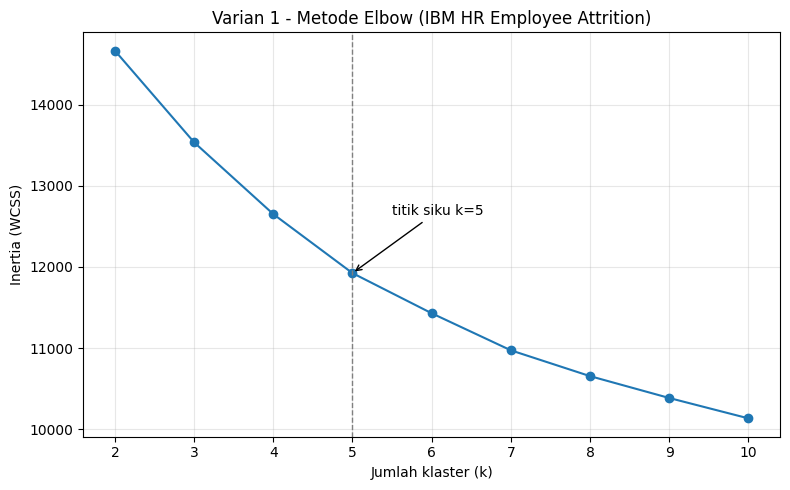


Tersimpan: data/hasil_varian/varian1.json  dan  gambar/varian1_elbow.png
Commit berkas ini dengan akun GitHub Anda sendiri.


In [6]:
import importlib
import matplotlib
import matplotlib.pyplot as plt

import alat
importlib.reload(alat)
from alat import (jalankan_k, muat_bersih, simpan_hasil, skalakan, titik_siku)

print('=' * 70)
print('VARIAN 1 - PENENTUAN k DENGAN METODE ELBOW')
print('=' * 70)

df = muat_bersih()
X, _ = skalakan(df)
print(f'Data bersih kelompok: {df.shape[0]} baris, {df.shape[1]} fitur\n')

tabel = jalankan_k(X)
tabel['penurunan'] = tabel['inertia'].diff().abs()
tabel['penurunan_persen'] = (tabel['penurunan'] / tabel['inertia'].shift(1) * 100)
print(tabel[['k', 'inertia', 'penurunan', 'penurunan_persen', 'silhouette']]
      .round(3).to_string(index=False))

k_siku = titik_siku(tabel['k'], tabel['inertia'])
sil_siku = float(tabel.loc[tabel['k'] == k_siku, 'silhouette'].iloc[0])
inertia_siku = float(tabel.loc[tabel['k'] == k_siku, 'inertia'].iloc[0])

print(f'\nTitik siku  : k = {k_siku}')
print(f'Inertia     : {inertia_siku:,.2f}')
print(f'Silhouette  : {sil_siku:.4f}  (metrik pendukung, bukan dasar varian ini)')
print('\nCara menentukannya: titik siku diambil pada jarak tegak lurus terjauh')
print('dari garis yang menghubungkan k terkecil dan k terbesar. Cara ini')
print('menggantikan penilaian dengan mata, yang sering berbeda antarorang.')

plt.figure(figsize=(8, 5))
plt.plot(tabel['k'], tabel['inertia'], marker='o')
plt.axvline(k_siku, ls='--', lw=1, color='grey')
plt.annotate(f'titik siku k={k_siku}', xy=(k_siku, inertia_siku),
             xytext=(k_siku + 0.5, inertia_siku * 1.06),
             arrowprops=dict(arrowstyle='->', lw=1))
plt.xlabel('Jumlah klaster (k)'); plt.ylabel('Inertia (WCSS)')
plt.title('Varian 1 - Metode Elbow (IBM HR Employee Attrition)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('gambar/varian1_elbow.png', dpi=110)
plt.show()

jalur = simpan_hasil(1, {
    'varian': 1,
    'nama': 'Penentuan k (Metode Elbow)',
    'yang_diubah': 'Jumlah klaster ditentukan dari titik siku kurva inertia',
    'fitur_dipakai': df.columns.tolist(),
    'k_terpilih': k_siku,
    'metrik_utama': {'silhouette': round(sil_siku, 4)},
    'metrik_pendukung': {'inertia': round(inertia_siku, 2)},
    'tabel_k': tabel[['k', 'inertia', 'silhouette', 'davies_bouldin']]
                .round(4).to_dict(orient='records'),
})
print(f'\nTersimpan: {jalur}  dan  gambar/varian1_elbow.png')
print('Commit berkas ini dengan akun GitHub Anda sendiri.')

## 2.3 Yang harus Anda tulis sendiri

Rubrik varian perorangan menilai tiga hal: **ketepatan implementasi**, **kebenaran evaluasi**, dan **kedalaman interpretasi**. Butir ketiga tidak dapat dihasilkan oleh kode, dan di situlah nilai paling banyak hilang.

1. **Apa arti titik siku ini dalam konteks kasus kelompok Anda? Jawab dengan menyebut jumlah segmen karyawan, bukan hanya angka k.**
   Berdasarkan metode jarak tegak lurus terjauh dari garis penghubung $k = 2$ ke $k = 10$, titik siku jatuh pada **$k = 5$** dengan nilai inertia **11.924,13** (turun 5,75% dari $k = 4$, lalu penurunan melambat menjadi 4,15% saat masuk $k = 6$). Dalam konteks dataset *IBM HR Employee Attrition*, hasil ini berarti 1.470 karyawan secara alami paling proporsional dikelompokkan menjadi **lima segmen profil karyawan** berdasarkan kombinasi usia, pendapatan bulanan, pengalaman kerja, lama bekerja di perusahaan, jarak promosi terakhir, mobilitas perusahaan, jarak tempat tinggal, empat skor kepuasan/keterlibatan, dan status lembur. Menambah segmen lebih dari lima mulai memberi pengurangan variasi internal (*inertia*) yang semakin kecil per tambahan klaster.

2. **Seberapa tegas sikunya? Bila tumpul, nilai k mana saja yang masuk akal, dan apa pertimbangan memilih salah satunya?**
   Tekukan siku pada kurva inertia tergolong **tumpul (melandai secara bertahap)**, bukan patah tajam. Penurunan persentase inertia berlangsung landai: 7,70% ($k = 2 \to 3$), 6,54% ($k = 3 \to 4$), 5,75% ($k = 4 \to 5$), lalu baru turun lebih jelas ke 4,15% ($k = 5 \to 6$) dan di bawah 3% setelah $k = 7$. Kurva yang tumpul ini wajar pada data karyawan berdimensi 12 fitur karena atribut kepuasan ordinal dan perilaku kerja cenderung menyebar merata tanpa sekat tajam. Oleh karena itu, kandidat yang masih masuk akal berada di rentang **$k = 3, 4,$ hingga $5$**. Pada Varian 1 ini dipilih **$k = 5$** secara objektif lewat metode jarak tegak lurus terjauh agar tidak bergantung pada penilaian visual semata, sementara nilai $k$ lebih ringkas (seperti 3 atau 4 segmen) tetap layak dipertimbangkan di Bagian 5 jika metrik validasi lain menunjukkan pemisahan yang lebih baik.

3. **Apa yang berubah pada aplikasi web bila k Anda yang dipakai?**
   Bila $k = 5$ yang dipilih untuk model final, maka aplikasi web segmentasi karyawan harus menyediakan **lima profil segmen yang berbeda**, lengkap dengan **lima nama segmen yang bermakna** dan **lima rekomendasi tindakan HR yang spesifik** (satu untuk tiap klaster). Dari sisi antarmuka pengguna, form masukan fitur tetap sama, tetapi cakupan penafsiran keluaran lebih rinci dibandingkan 3 atau 4 segmen—keuntungannya rekomendasi bisa lebih terarah ke sub-profil karyawan, sedangkan konsekuensinya tim harus memastikan kelima segmen benar-benar punya pembeda praktis dan bukan sekadar pecahan kecil yang tumpang tindih.

4. **Dugaan Anda: apakah Silhouette dan Davies-Bouldin akan menunjuk k yang sama? *(Ditulis sebelum melihat hasil Anggota 2 dan Anggota 3)***
   Dugaan saya, **Silhouette Score dan Davies-Bouldin Index kemungkinan besar akan menunjuk nilai $k$ yang lebih kecil daripada $k = 5$** (kemungkinan besar di $k = 2$ atau $k = 3$). Alasannya, Metode Elbow hanya mengukur kerapatan internal (*inertia*) yang terus menurun saat $k$ bertambah sehingga cenderung menemukan kompromi di tengah rentang uji ($k = 4\text{–}6$). Sebaliknya, Silhouette dan Davies-Bouldin sama-sama memperhitungkan **jarak pemisahan antarklaster**; pada data HR dengan 12 fitur yang kurva sikunya tumpul, membagi data menjadi 5 kelompok membuat batas antarklaster makin berdekatan (terlihat dari nilai Silhouette pendukung pada $k = 5$ yang hanya `0,1126`, lebih rendah daripada `0,2003` pada $k = 2$). Dugaan ini akan diuji langsung pada tabel perbandingan Bagian 5.

## 2.4 Unduh, commit, dan teruskan

In [7]:
# Unduh hasil Bagian 2, lalu commit ke repositori dengan akun GitHub
# ANDA SENDIRI. Riwayat commit adalah bukti penilaian perorangan.
from google.colab import files
files.download('data/hasil_varian/varian1.json')
files.download('gambar/varian1_elbow.png')
print()
print('Langkah berikutnya:')
print('  1. Commit data/hasil_varian/varian1.json dan gambar/varian1_elbow.png dengan akun GitHub Anda sendiri.')
print('  2. File -> Download -> Download .ipynb, beri nama 03_varian_1.ipynb,')
print('     lalu commit ke folder notebook/ dengan akun GitHub Anda sendiri.')
print('  3. Berkas varian1.json sudah otomatis tersimpan di folder Drive kelompok untuk Bagian 5.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Langkah berikutnya:
  1. Commit data/hasil_varian/varian1.json dan gambar/varian1_elbow.png dengan akun GitHub Anda sendiri.
  2. File -> Download -> Download .ipynb, beri nama 03_varian_1.ipynb,
     lalu commit ke folder notebook/ dengan akun GitHub Anda sendiri.
  3. Berkas varian1.json sudah otomatis tersimpan di folder Drive kelompok untuk Bagian 5.


## Checklist Bagian 2

- [x] `varian1.json` ter-commit di `data/hasil_varian/`
- [x] `varian1_elbow.png` ter-commit di `gambar/`
- [x] Notebook ini diunduh (dalam keadaan seluruh keluaran sel tampil), diberi nama `03_varian_1.ipynb`, dan ter-commit di `notebook/`
- [x] Commit dilakukan dengan akun GitHub Anggota 1 (Noval Adrian) sendiri
- [x] Keempat jawaban di sel 2.3 sudah diperiksa dan sesuai pemahaman sendiri (termasuk dugaan hasil Anggota 2 & 3 sebelum melihat hasilnya)
- [x] Tidak mengubah rumus `alat.py` maupun `SEED = 42`
- [x] Siap menjelaskan Varian 1 selama 5 menit tanpa membaca naskah pada Progres 2